In [16]:
from pandas.conftest import axis
from pandas.core.computation.expressions import where
!pip install cvxpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 5.6 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 5.8 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pyparsing import alphas

In [3]:


model_name="alexnet"
dataset_name="cifar10"
max_files=100
layer_name="gradients.classifier.4.weight"
#layer_name="gradients.features.10.weight"
constraint_gradients= np.random.randint(0,30_000,1000)
splits = [0,1]
top_k=2000

gradients_per_file=20

total_splits = len(splits)
total_gradientes=gradients_per_file*max_files


max_componentes_por_iteracion=np.zeros((total_splits,total_gradientes,top_k))
norms=np.zeros((total_splits, total_gradientes, 3))
gradientes=None

for i in range(max_files):
    top_k_comp_idx=None
    for split in splits:
        if split is not None:
            path=f"./data/gradientes/split/{model_name}/{dataset_name}/{split}/{layer_name}.{i}.npz"
        else:
            path=f"./data/gradientes/{model_name}/{dataset_name}/{layer_name}.{i}.npz"
        data = np.load(path)["arr_0"]
        g_flat = data.reshape(gradients_per_file, -1)
        split_idx=split if split is not None else 0

        print(f"Iter {i}/{split_idx}",g_flat.shape,data.shape)

        idx_start = i * gradients_per_file
        idx_end = idx_start + gradients_per_file

        norms[split_idx,idx_start:idx_end, 0] = np.linalg.norm(g_flat, axis=1, ord=np.inf)
        norms[split_idx,idx_start:idx_end, 1] = np.linalg.norm(g_flat, axis=1, ord=1)
        norms[split_idx,idx_start:idx_end, 2] = np.linalg.norm(g_flat, axis=1)

        if constraint_gradients is None:
            if gradientes is None:
                gradientes=np.zeros((len(splits),total_gradientes,g_flat.shape[1]))
            gradientes[split_idx,idx_start:idx_end]=g_flat
        else:
            if gradientes is None:
                gradientes=np.zeros((len(splits),total_gradientes,len(constraint_gradients)))
            gradientes[split_idx,idx_start:idx_end]=g_flat[:,constraint_gradients]

        if top_k_comp_idx is None:
            top_k_comp_idx=np.argpartition(np.abs(g_flat), -top_k, axis=1)[:, -top_k:]
            #print(top_k_comp_idx.shape)

        max_componentes_por_iteracion[split_idx,idx_start:idx_end,:]=np.take_along_axis(g_flat, top_k_comp_idx, axis=1)



Iter 0/0 (20, 16777216) (20, 4096, 4096)
Iter 0/1 (20, 16777216) (20, 4096, 4096)
Iter 1/0 (20, 16777216) (20, 4096, 4096)
Iter 1/1 (20, 16777216) (20, 4096, 4096)
Iter 2/0 (20, 16777216) (20, 4096, 4096)
Iter 2/1 (20, 16777216) (20, 4096, 4096)
Iter 3/0 (20, 16777216) (20, 4096, 4096)
Iter 3/1 (20, 16777216) (20, 4096, 4096)
Iter 4/0 (20, 16777216) (20, 4096, 4096)
Iter 4/1 (20, 16777216) (20, 4096, 4096)
Iter 5/0 (20, 16777216) (20, 4096, 4096)
Iter 5/1 (20, 16777216) (20, 4096, 4096)
Iter 6/0 (20, 16777216) (20, 4096, 4096)
Iter 6/1 (20, 16777216) (20, 4096, 4096)
Iter 7/0 (20, 16777216) (20, 4096, 4096)
Iter 7/1 (20, 16777216) (20, 4096, 4096)
Iter 8/0 (20, 16777216) (20, 4096, 4096)
Iter 8/1 (20, 16777216) (20, 4096, 4096)
Iter 9/0 (20, 16777216) (20, 4096, 4096)
Iter 9/1 (20, 16777216) (20, 4096, 4096)
Iter 10/0 (20, 16777216) (20, 4096, 4096)
Iter 10/1 (20, 16777216) (20, 4096, 4096)
Iter 11/0 (20, 16777216) (20, 4096, 4096)
Iter 11/1 (20, 16777216) (20, 4096, 4096)
Iter 12/0 (2

In [5]:
gradientes.shape

(2, 2000, 1000)

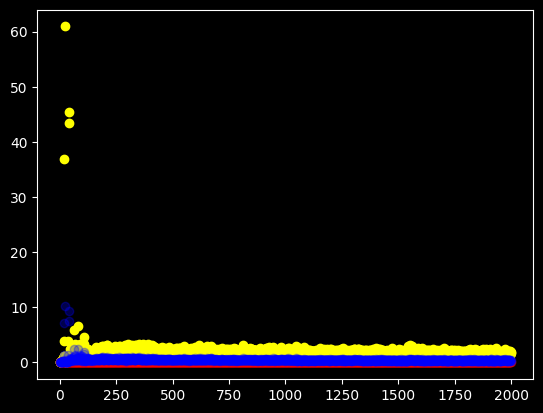

In [13]:


#plt.yscale("log")
plt.scatter(np.arange(total_gradientes),np.abs(norms[0,:,2]),c='yellow')
plt.scatter(np.arange(total_gradientes),np.abs(np.linalg.norm(gradientes[0,:,:],axis=1)),alpha=0.3,c='red')
plt.scatter(np.arange(total_gradientes),np.abs(np.linalg.norm(max_componentes_por_iteracion[0,:,:],axis=1)),alpha=0.3,c='blue')

(array([0.00333333, 0.00333333, 0.00333333, 0.00333333, 0.00333333,
        0.00333333, 0.00333333, 0.00333333, 0.00333333, 0.00333333,
        0.00333333, 0.00333333, 0.00333333, 0.00333333, 0.01      ,
        0.01      , 0.01333333, 0.02333333, 0.02666667, 0.98      ,
        0.99      , 0.99      , 0.99      , 0.99      , 0.99333333,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99666667, 0.99666667,
        0.99666667, 0.99666667, 0.99666667, 0.99

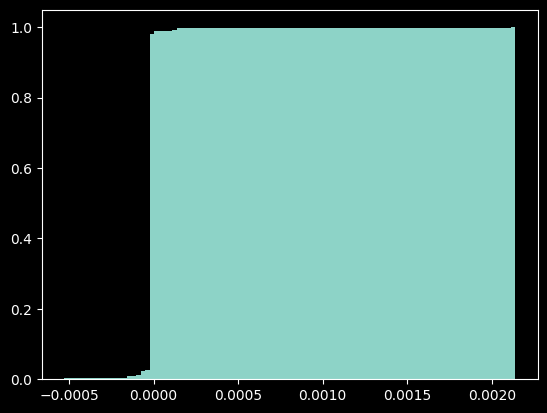

In [159]:
from scipy.stats import alpha,levy_stable
gradientes[:,0]
plt.hist(gradientes[0,:,1],bins=100,cumulative=True,density=True)
#plt.hist(np.random.normal(0,0.01,total_gradientes),bins=100,alpha=0.5)
#plt.hist(np.random.standard_cauchy(total_gradientes)*0.0001,bins=100,alpha=0.5)
#plt.hist(levy_stable.rvs(1.6,beta=0,loc=0,scale=5e-3,size=total_gradientes),bins=100,alpha=0.5,color='red')
#plt.hist(np.random.normal(0,60*np.var(gradientes[0,:,100]),size=total_gradientes),bins=100,alpha=0.5,color='blue')
#plt.xlim((-0.05,0.05))
#alpha.rvs(2,size=total_gradientes)

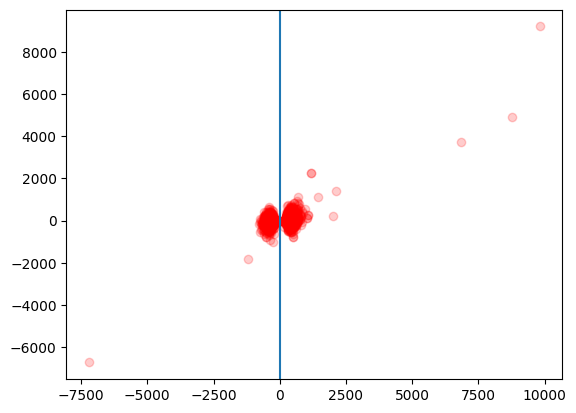

In [70]:
coord=11
f=5e4
A=gradientes
A=max_componentes_por_iteracion
#plt.xlim((-10,10))
#plt.ylim((-10,10))
plt.axvline(0)
plt.scatter(A[0,:,coord]*f,A[1,:,coord]*f,c='red',alpha=0.2)#,#c=np.arange(total_gradientes),cmap='viridis',alpha=0.2)
#plt.yscale("log")
#plt.xscale("log")

#plt.show()
#plt.show()
#plt.yscale('log')
#plt.xscale('log')

((2000,),
 array([0.92172646, 0.9412539 , 0.93967472, ..., 0.29053943, 0.43971274,
        0.22511188], shape=(2000,)))

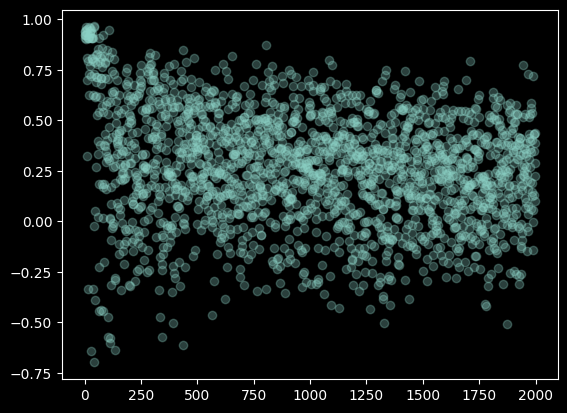

In [175]:

A=max_componentes_por_iteracion[0,:,0:100]
#B=np.roll(A,axis=0,shift=1)
B=max_componentes_por_iteracion[1,:,0:100]
#print(A.shape)
#assert np.abs(np.sum(A[0,:]-B[1,:]))<=1e-9
A_norm =A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cosine_dist=np.sum(A_norm*B_norm,axis=1)
plt.scatter(np.arange(total_gradientes),cosine_dist,alpha=.3)
cosine_dist.shape,cosine_dist

(array([0.19, 0.29, 0.32, 0.46, 0.5 , 0.59, 0.61, 0.66, 0.7 , 0.71, 0.73,
        0.76, 0.81, 0.87, 0.89, 0.9 , 0.96, 0.96, 0.96, 1.  ]),
 array([0.03502816, 0.08233656, 0.12964495, 0.17695335, 0.22426174,
        0.27157014, 0.31887854, 0.36618693, 0.41349533, 0.46080372,
        0.50811212, 0.55542051, 0.60272891, 0.6500373 , 0.6973457 ,
        0.7446541 , 0.79196249, 0.83927089, 0.88657928, 0.93388768,
        0.98119607]),
 <BarContainer object of 20 artists>)

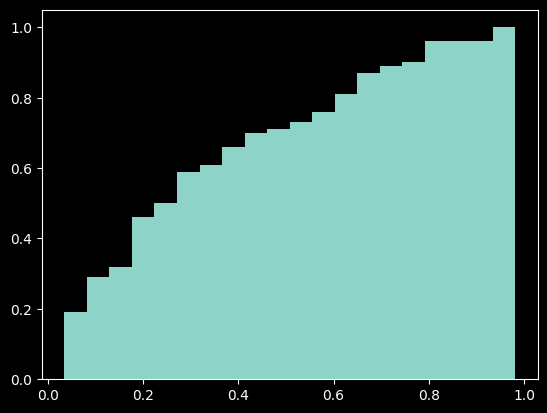

In [7]:
plt.hist(1-np.abs(cosine_dist),bins=20,density=True,cumulative=True)

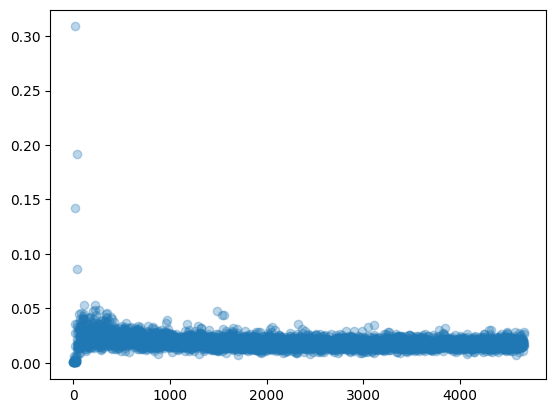

In [67]:
#plt.yscale("log")
sub_conjunto=[1,2,3,4,5,6,12]
A=max_componentes_por_iteracion[0,:,sub_conjunto]
B=np.roll(A,axis=0,shift=1)
B=max_componentes_por_iteracion[1,:,sub_conjunto]
plt.scatter(np.arange(total_gradientes),np.linalg.norm((A-B),axis=0),alpha=0.3)

In [1]:
n=1000
print("Sparsity real:", np.sum(np.abs(max_componentes_por_iteracion[1,0,0:n]) > 1e-6))
print("Sparsity real 2:", np.sum(np.abs(gradientes[1,0,0:n]) > 1e-6))
print(np.min(np.abs(max_componentes_por_iteracion[1,0,0:n])))
print(np.max(np.abs(max_componentes_por_iteracion[1,0,0:n])))
print(np.linalg.norm(max_componentes_por_iteracion[1,0,0]/np.linalg.norm(max_componentes_por_iteracion[1,0,0])))


NameError: name 'np' is not defined

(1000,)
Iter 0
Iter 50
Iter 100
Iter 150
Iter 200
Iter 250
Iter 300
Iter 350
Iter 400
Iter 450
Iter 500
Iter 550
Iter 600
Iter 650
Iter 700
Iter 750
Iter 800
Iter 850
Iter 900
Iter 950


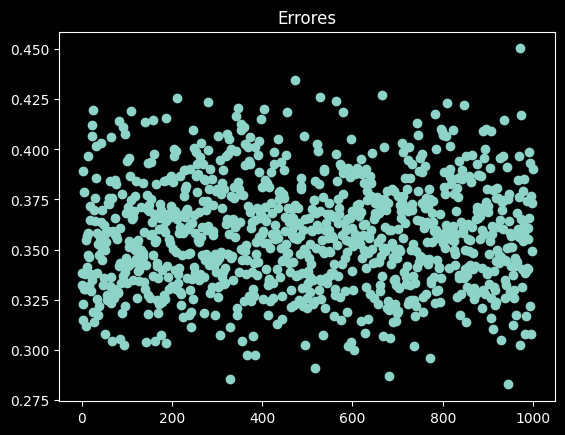

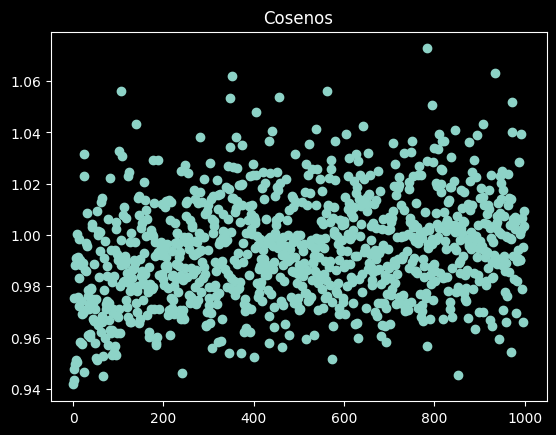

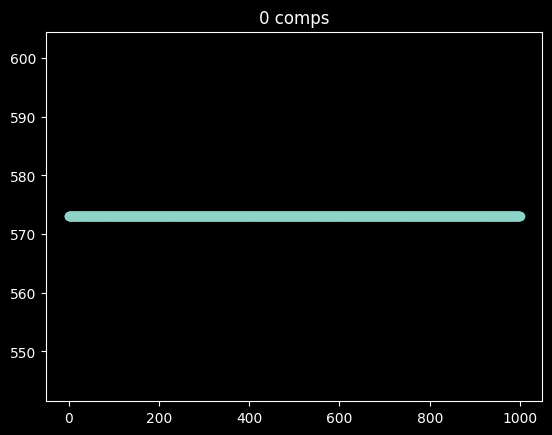

In [20]:
import cvxpy as cp
def sample_gaussian(n,m):
    return (1/np.sqrt(n))*(np.random.normal(size=(m,n)))
n=1000
X_true=gradientes[0,500,0:n]
#X_true=max_componentes_por_iteracion[1,99,0:n]
X_true=X_true*1e4
m=int(n*.45)
print(X_true.shape)
X_est=None
min_prob=None
err = 1e12
P=1000
errores_sensing = np.zeros((P))
cosines_sensing = np.zeros((P))
zero_components = np.zeros((P))
for j in range(P):
    if j % 50 == 0:
        print(f"Iter {j}")
    for i in range(1):
        G=sample_gaussian(n,m)
        Y=G.dot(X_true)
        X = cp.Variable(n)


        # Problema: minimizar norma L1
        objective = cp.Minimize(cp.norm1(X))
        constraints = [G @ X == Y]

        prob = cp.Problem(objective, constraints)

        # Resolver
        prob.solve()#solver=cp.SCS)#verbose=True,
        error_iter= np.linalg.norm(X_true-X.value)
        if err>error_iter:
            err = error_iter
            min_prob = prob
            X_est = X.value
        errores_sensing[j]=error_iter/np.linalg.norm(X_true)
        cosines_sensing[j]=X_true.T.dot(X_est)/(np.linalg.norm(X_true)*np.linalg.norm(X.value))
        zero_components[j]=np.sum(np.abs(X_true) > 1e-6)

# Resultado
#print("Non zero components:", )
#print("m:",m,f"({m*100/n} %)")

#print("Status:", min_prob.status)
#print(
#    "Norma del error:",np.linalg.norm(X_true - X_est*np.linalg.norm(X_true)/np.linalg.norm(X_est)),
#    "\nNorma del vector original:",np.linalg.norm(X_true),
#      "\nDistancia del coseno",)
#print("X estimado:\n", X.value)
#print("X real:\n", X_true)
plt.scatter(np.arange(P),errores_sensing)
plt.title("Errores")
plt.show()
plt.title("Cosenos")
plt.scatter(np.arange(P),cosines_sensing)
plt.show()
plt.title("0 comps")
plt.scatter(np.arange(P),zero_components)

(1000,)
Iter 0


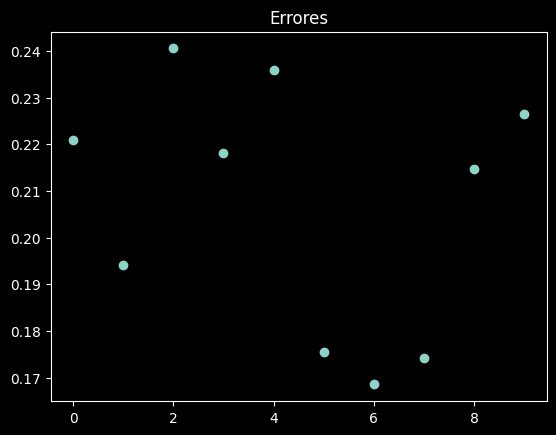

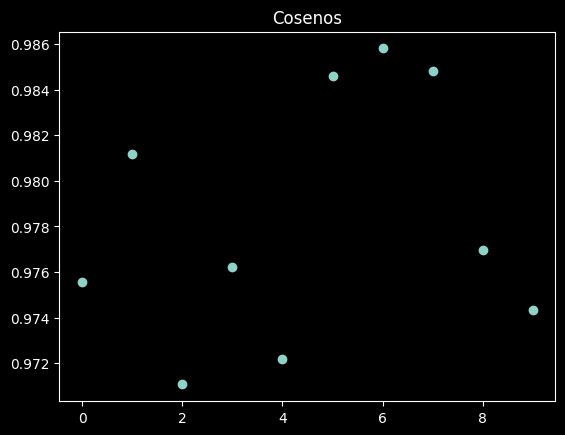

Valores 0.24053843483112577 0.16852811620849711


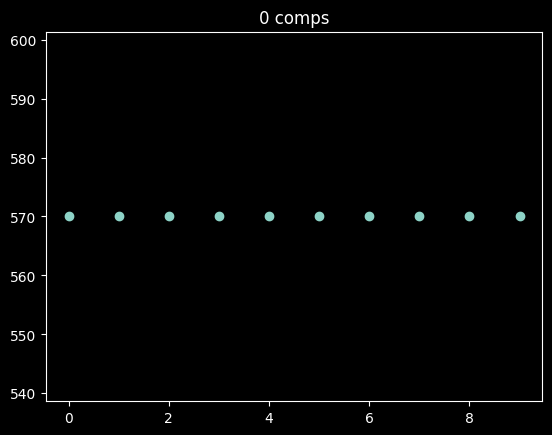

In [14]:
%%sql
import cvxpy as cp
def sample_gaussian(n,m):
    return (1/np.sqrt(n))*(np.random.normal(size=(m,n)))
n=1000
X_true=gradientes[0,500,0:n]
#X_true=max_componentes_por_iteracion[1,99,0:n]
X_true=X_true*1e4
m=int(n*.6)
print(X_true.shape)
X_est=None
min_prob=None
err = 1e12
P=10
errores_sensing = np.zeros((P))
cosines_sensing = np.zeros((P))
zero_components = np.zeros((P))
for j in range(P):
    if j % 50 == 0:
        print(f"Iter {j}")
    for i in range(1):
        G=sample_gaussian(n,m)
        Y=G.dot(X_true)
        X = cp.Variable(n)


        # Problema: minimizar norma L1
        objective = cp.Minimize(cp.norm1(X))
        constraints = [G @ X == Y]

        prob = cp.Problem(objective, constraints)

        # Resolver
        prob.solve()#solver=cp.SCS)#verbose=True,
        X_est=X.value
        #X_est=X_est * (np.linalg.norm(X_true)/np.linalg.norm(X_est))
        X_est_unit=X_est/np.linalg.norm(X_est)
        X_true_unit=X_true/np.linalg.norm(X_true)
        assert abs(np.linalg.norm(X_est_unit)-1)<1e-12
        assert abs(np.linalg.norm(X_true_unit)-1)<1e-12

        error_iter= np.linalg.norm(X_true_unit-X_est_unit)

        errores_sensing[j]=error_iter#/np.linalg.norm(X_true)
        cosines_sensing[j]=X_true.T.dot(X_est)/(np.linalg.norm(X_true)*np.linalg.norm(X.value))
        zero_components[j]=np.sum(np.abs(X_true) > 1e-6)

# Resultado
#print("Non zero components:", )
#print("m:",m,f"({m*100/n} %)")

#print("Status:", min_prob.status)
#print(
#    "Norma del error:",np.linalg.norm(X_true - X_est*np.linalg.norm(X_true)/np.linalg.norm(X_est)),
#    "\nNorma del vector original:",np.linalg.norm(X_true),
#      "\nDistancia del coseno",)
#print("X estimado:\n", X.value)
#print("X real:\n", X_true)

plt.scatter(np.arange(P),errores_sensing)
plt.title("Errores")
plt.show()
plt.title("Cosenos")
plt.scatter(np.arange(P),cosines_sensing)
plt.show()
plt.title("0 comps")
plt.scatter(np.arange(P),zero_components)
print("Valores", np.max(errores_sensing),np.min(errores_sensing))

1.8181818181818181

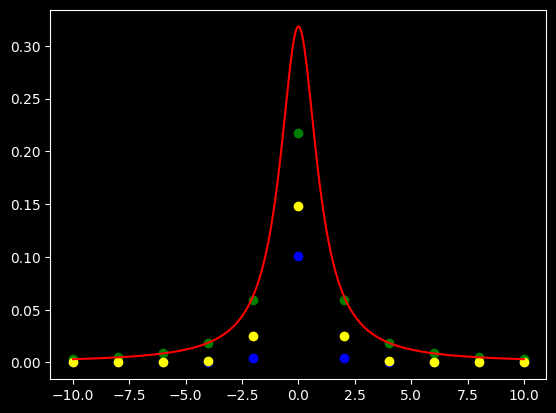

In [21]:
def test_pdf(X):
    return 1/(np.pi*(1+X**2))
X_lim=10
cent_count=10
dist=2*X_lim/(1+cent_count)
X=np.linspace(-X_lim,X_lim,1000)

plt.plot(X,test_pdf(X),color='red')
cents= np.linspace(-X_lim,X_lim,cent_count+1)
plt.scatter(cents, test_pdf(cents)**2, color='blue' )
plt.scatter(cents, test_pdf(cents)*(1-test_pdf(cents)), color='green' )
plt.scatter(cents, test_pdf(cents)*(test_pdf(cents)+test_pdf(cents+dist)+test_pdf(cents-dist)), color='yellow' )

dist

[0. 0.] (2, 5)
[0. 0.] (2, 25)
[0. 0.] (2, 125)
[0. 0.] (2, 7)
[0. 0.] (2, 49)
[0. 0.] (2, 343)
[0. 0.] (2, 13)
[0. 0.] (2, 169)
[0. 0.] (2, 2197)
[0. 0.] (2, 5)
[0. 0.] (2, 25)
[0. 0.] (2, 125)
[0. 0.] (2, 7)
[0. 0.] (2, 49)
[0. 0.] (2, 343)
[0. 0.] (2, 13)
[0. 0.] (2, 169)
[0. 0.] (2, 2197)
[0. 0.] (2, 5)
[0. 0.] (2, 25)
[0. 0.] (2, 125)
[0. 0.] (2, 7)
[0. 0.] (2, 49)
[0. 0.] (2, 343)
[0. 0.] (2, 13)
[0. 0.] (2, 169)
[0. 0.] (2, 2197)
[0. 0.] (2, 5)
[0. 0.] (2, 25)
[0. 0.] (2, 125)
[0. 0.] (2, 7)
[0. 0.] (2, 49)
[0. 0.] (2, 343)
[0. 0.] (2, 13)
[0. 0.] (2, 169)
[0. 0.] (2, 2197)
[0. 0.] (2, 5)
[0. 0.] (2, 25)
[0. 0.] (2, 125)
[0. 0.] (2, 7)
[0. 0.] (2, 49)
[0. 0.] (2, 343)
[0. 0.] (2, 13)
[0. 0.] (2, 169)
[0. 0.] (2, 2197)


/tmp/ipykernel_1857887/3776641270.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([H_s[t_idx, g_idx, k, :] for k in range(K)],
/tmp/ipykernel_1857887/3776641270.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([H_s[t_idx, g_idx, k, :] for k in range(K)],
/tmp/ipykernel_1857887/3776641270.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([H_s[t_idx, g_idx, k, :] for k in range(K)],
/tmp/ipykernel_1857887/3776641270.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be 

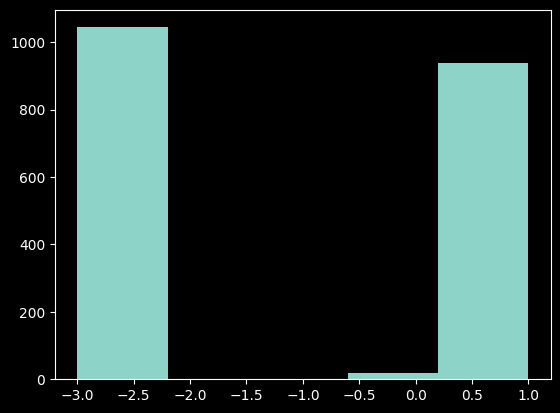

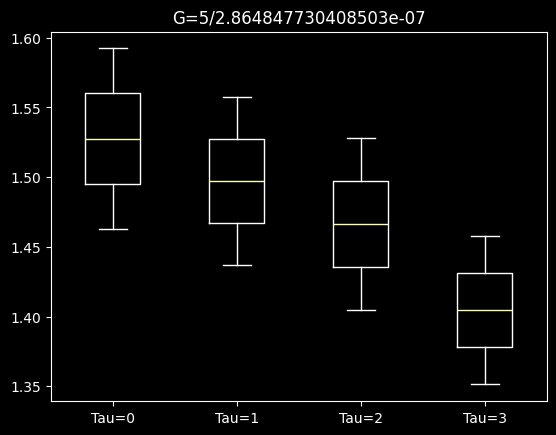

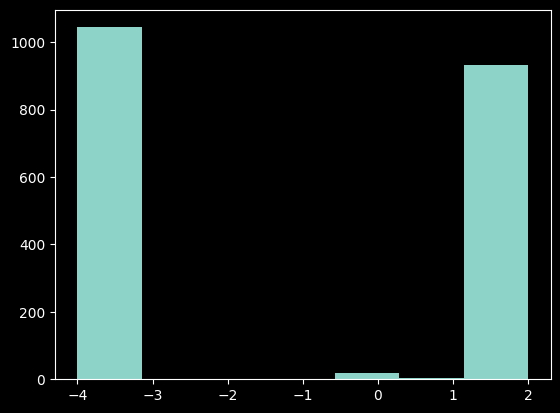

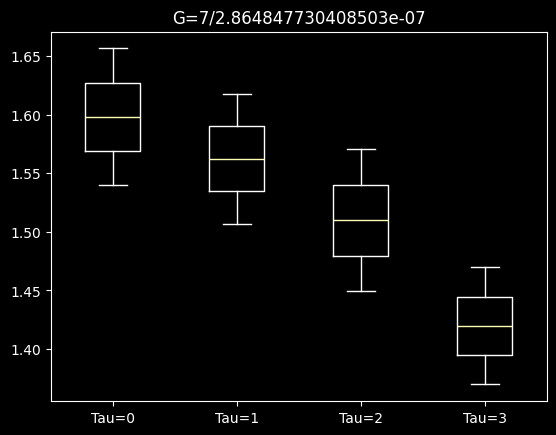

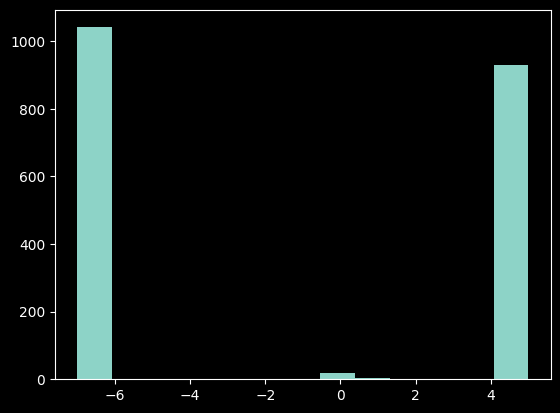

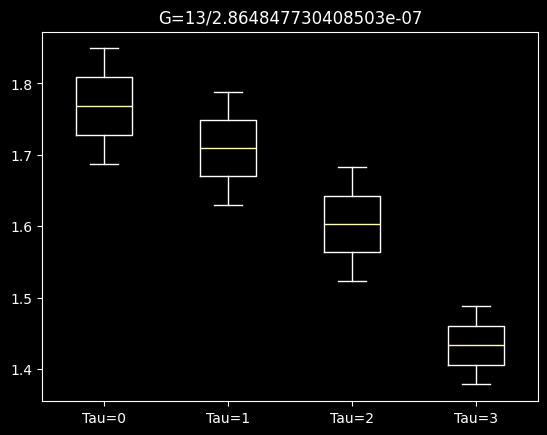

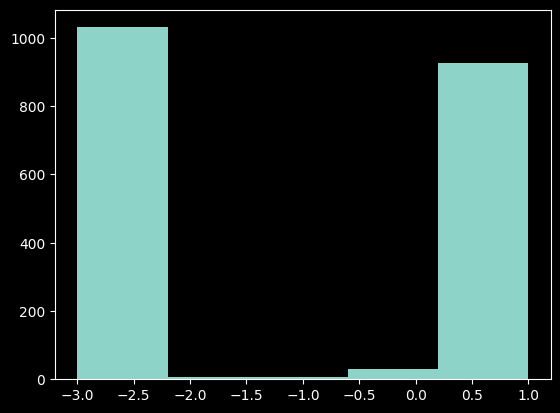

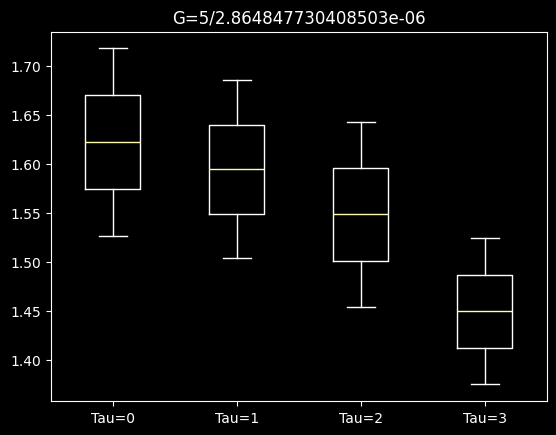

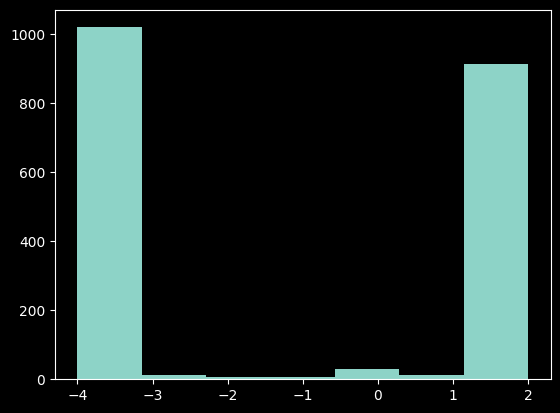

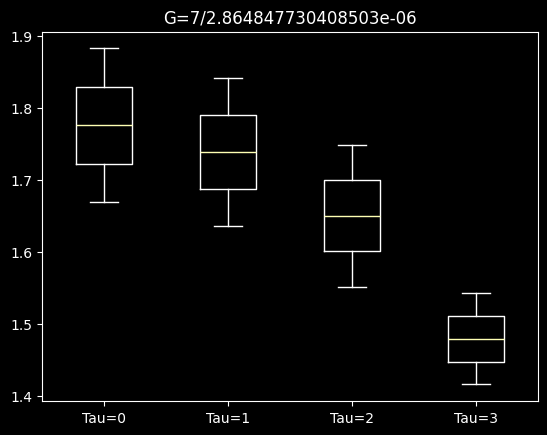

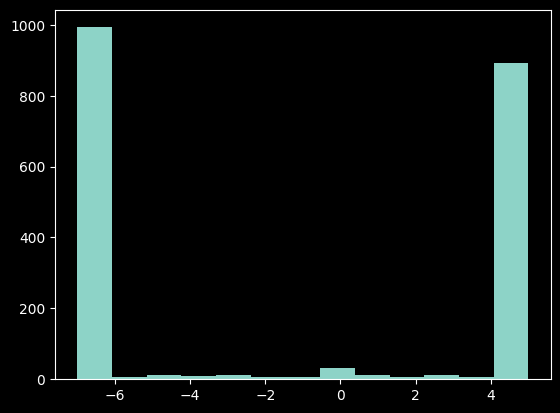

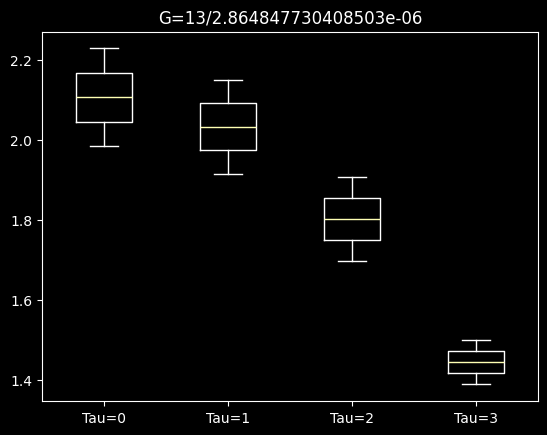

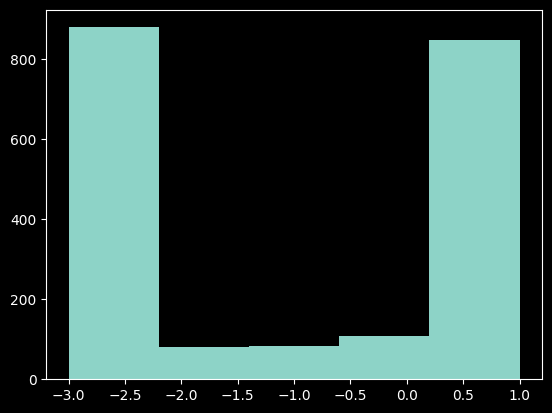

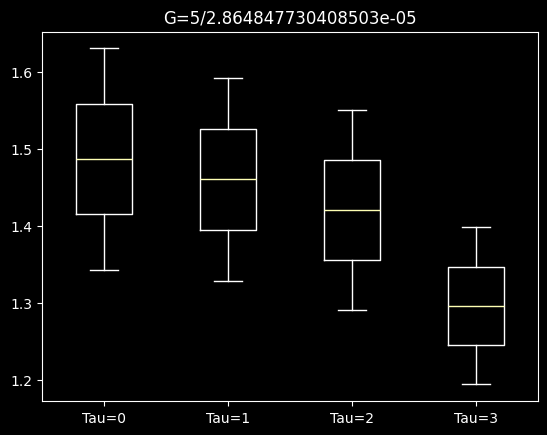

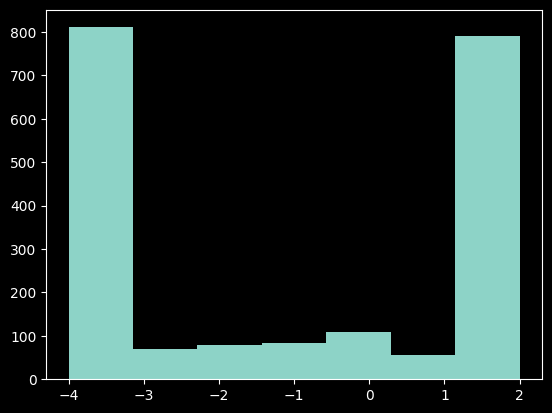

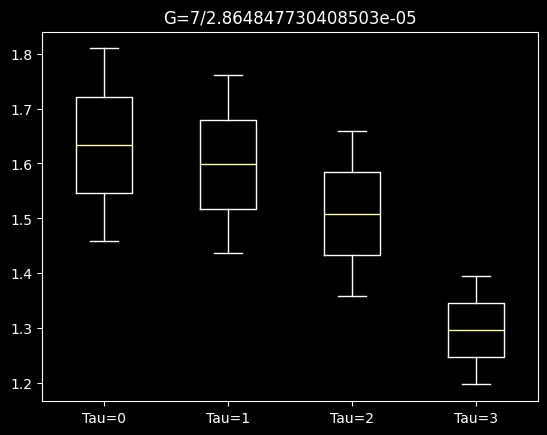

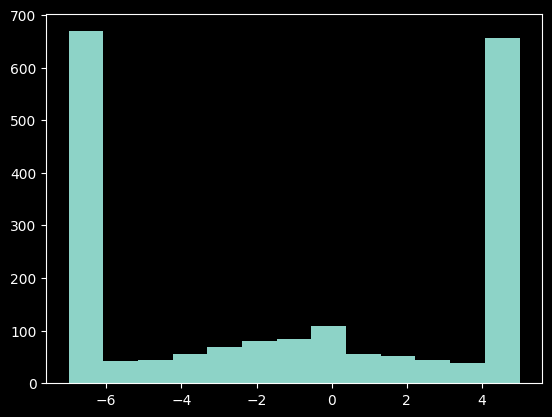

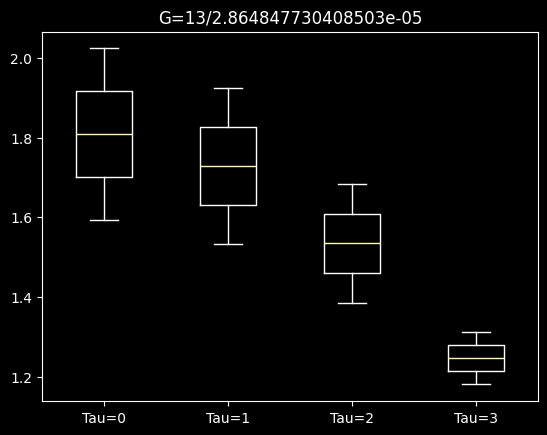

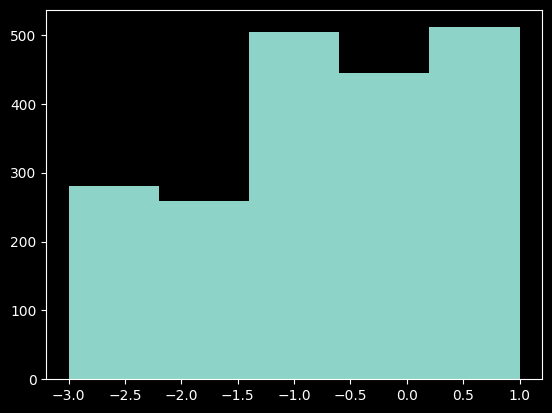

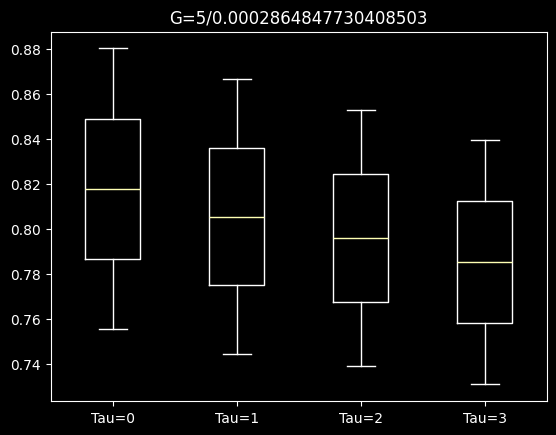

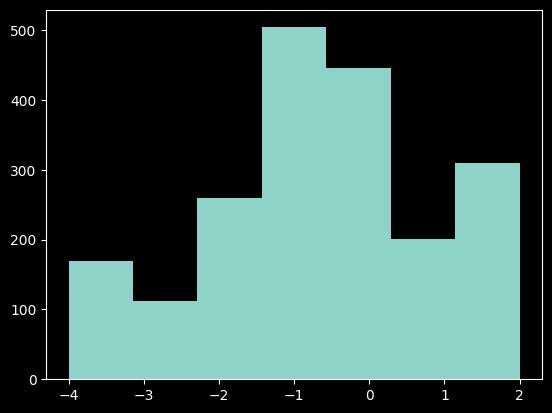

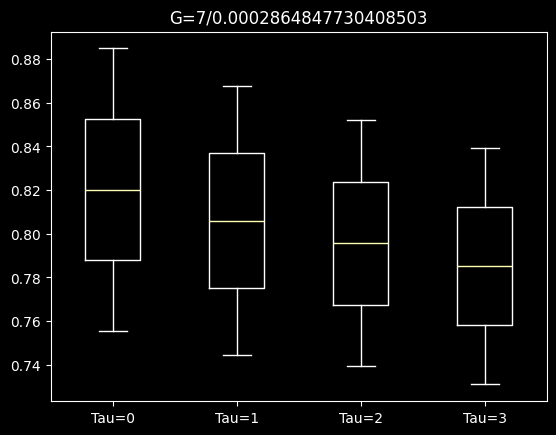

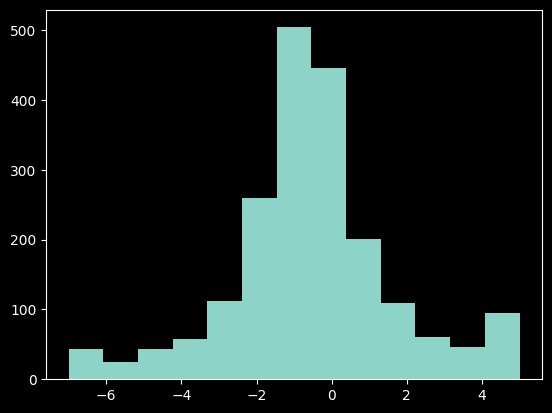

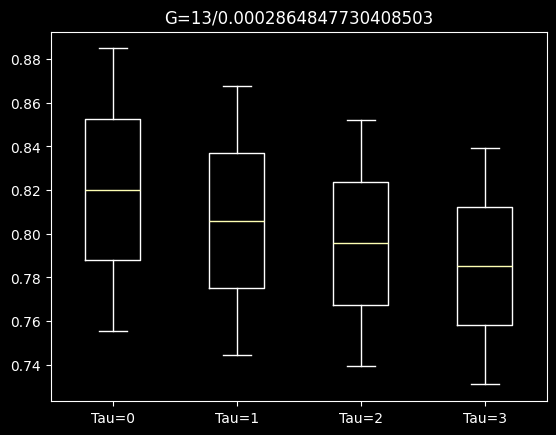

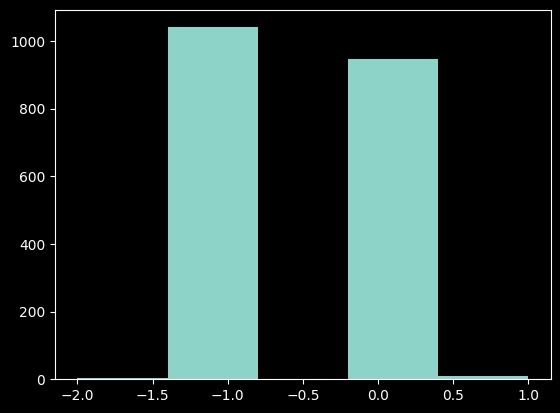

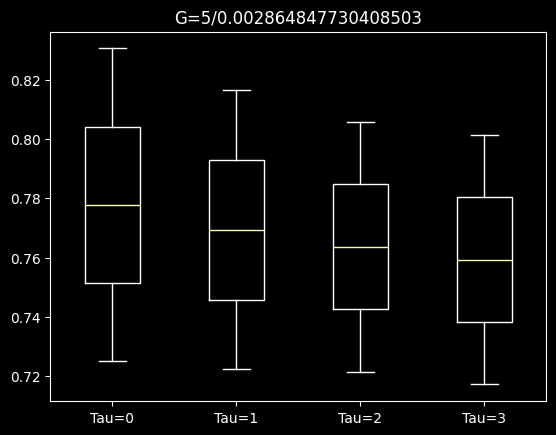

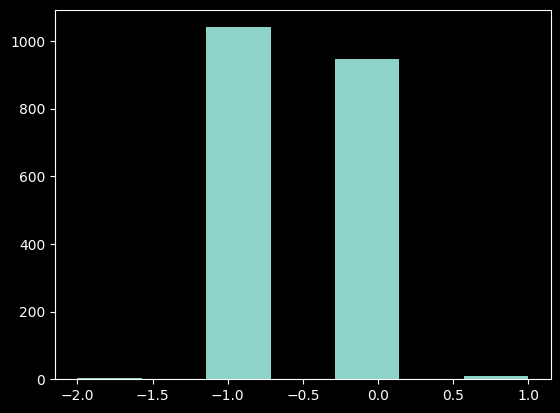

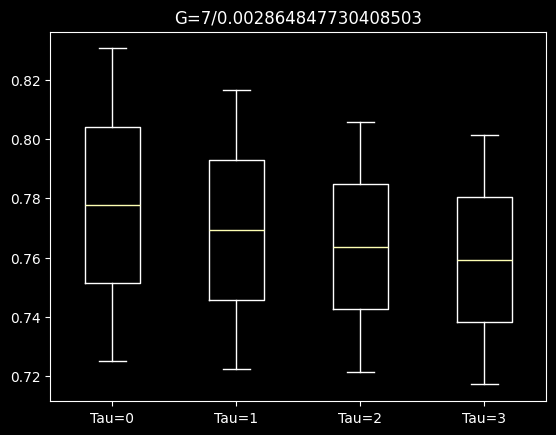

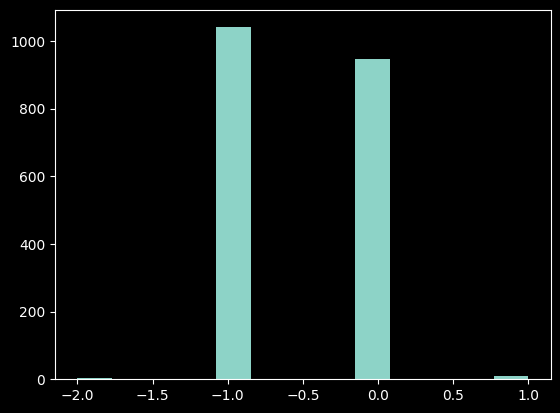

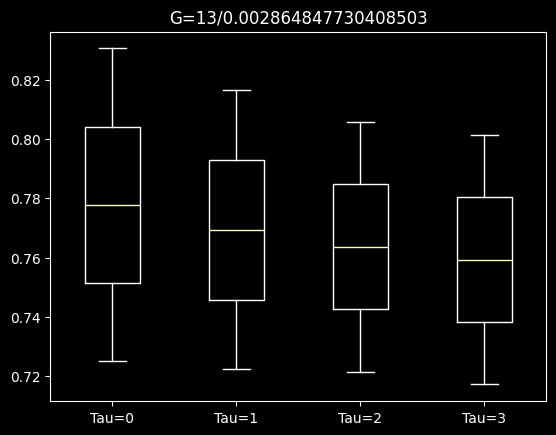

<Figure size 640x480 with 0 Axes>

In [174]:
def H(Probs,Ponderacion=None,axis=None):
    log_p=np.zeros_like(Probs)
    np.log2(Probs,out=log_p,where=Probs!=0)
    if Ponderacion is not None:
        return -np.sum(Ponderacion*Probs*log_p,axis=axis)
    else:
        return -np.sum(Probs*log_p,axis=axis)
def entropy_rate(X, k, G, t, N=None,C=None):
    """
    X: array 2D (largo,num_componentes)
    k: orden del proceso
    G: número de niveles de cuantización
    t: tamaño de malla
    N: cantidad de datos a usar
    """
    N = N if N is not None else X.shape[0]
    C = C if C is not None else np.arange(0,X.shape[1])
    N_Comps= len(C)
    X=X[0:N,C]
    #Cantidad desde el estado anterior al nuevo estado
    E=np.zeros((N_Comps,G**k,G))
    #Cantidad por estado previo
    Cants=np.zeros((N_Comps,G**k))
    #Cantidad por simbolo
    Cants_0_order=np.zeros((N_Comps,G))

    #Quantización
    X_Q=((X//t).clip(-G//2,G//2-1)+(G//2)).astype(int)


    Indices = np.zeros( (N-k,N_Comps),dtype=int)
    for tau in range(k):
        Indices+=X_Q[tau:N-(k-tau),:]*G**tau
    #print(Indices)
    comp_idx = np.arange(N_Comps)[:, np.newaxis]

    Targets = X_Q[k:].T
    np.add.at(E, (comp_idx, Indices.T, Targets), 1)
    np.add.at(Cants, (comp_idx, Indices.T), 1)
    np.add.at(Cants_0_order, (comp_idx, X_Q.T), 1)
    assert np.sum(E.sum(axis=2)-Cants)<1e-6
    print(np.sum(Cants,axis=1)-(N-k),Cants.shape)
    assert np.sum(Cants.sum(axis=1)-(N-k))<1e-6

    P_k=Cants/(N-k)

    #Normalizamos la cantidad de estado previo -> estado nuevo
    Cantidad_Fila=np.sum(E,axis=2,keepdims=True)
    Cantidad_Fila=np.repeat(Cantidad_Fila,G,axis=2)
    assert Cantidad_Fila.shape[0]==N_Comps,f"{Cantidad_Fila.shape}"
    assert Cantidad_Fila.shape[1]==G**k,f"{Cantidad_Fila.shape}"
    assert Cantidad_Fila.shape[2]==G,f"{Cantidad_Fila.shape}"

    P_x_dado_pasado=np.zeros_like(E)
    np.divide(E,Cantidad_Fila,out=P_x_dado_pasado,where=Cantidad_Fila>0)
    #Si esta normalizado cada fila tiene que dar 1 la suma, si y solo si encontre
    # algo que me lleva del estado anterior al nuevo
    assert np.all(np.isclose(np.sum(P_x_dado_pasado,axis=2),1),where=Cantidad_Fila[:,:,0]>0)

    P_estado_anterior=np.repeat(Cants[:,:,np.newaxis],G,axis=2)/(N-k)

    assert P_estado_anterior.shape[0]==N_Comps
    assert P_estado_anterior.shape[1]==G**k
    H_proceso=H(P_x_dado_pasado,P_estado_anterior,axis=(1,2))

    H_k=H(P_k,axis=1)
    P_simbolo=Cants_0_order/N
    #Para cada componente la probabilidad tiene que dar 1
    assert np.allclose(np.sum(P_simbolo,axis=1),1)
    H_0=H(P_simbolo,axis=1)

    #assert H.shape==(N_Comps), f"{H.shape}"
    return P_x_dado_pasado,H_proceso,H_k,H_0

    #for t in range(k,N):
#print(gradientes.shape,gradientes[0,:,:].shape)
Cs=[1,2]
#t=np.var(gradientes[0,:,:])/100
T_mallas= np.var(gradientes[0,:,:])*10.**np.arange(0,5)
Gs=[2,5,7]
Gs=[5,7,13]
K=4
H_s=np.zeros((len(T_mallas),len(Gs),K,len(Cs)))

for (t_idx,t) in enumerate(T_mallas):
    for (g_idx,g) in enumerate(Gs):
        for k in range(1,K):
            _,Tasa_k,H_k,H_0=entropy_rate(gradientes[0,:,:],k=k,G=g,t=t,C=Cs)
            H_s[t_idx,g_idx,k,:]=Tasa_k
            H_s[t_idx,g_idx,0,:]=H_0
for (t_idx,t) in enumerate(T_mallas):


    for (g_idx,g) in enumerate(Gs):
        plt.hist(np.clip(gradientes[0,:,0]//t,-g//2,g//2-1),bins=g)
        plt.figure()
        plt.title(f"G={g}/{t}")
        plt.boxplot([H_s[t_idx, g_idx, k, :] for k in range(K)],
                    labels = [f"Tau={k}" for k in range(K)],)

        plt.figure()


